## Importing Relevant Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading The Dataset

In [2]:
from pathlib import Path
import pandas as pd

project_path = Path(
    r"C:\Users\HP\Downloads\kenyan_retail_synthetic (8)\kenyan_retail_synthetic"
)

print("Folder exists:", project_path.exists())
print("Files and folders:")
print(list(project_path.iterdir()))

Folder exists: True
Files and folders:
[WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/.git'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/data'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/data_sources.md'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/docs'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/milestone_2'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/README.md'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/reports'), WindowsPath('C:/Users/HP/Downloads/kenyan_retail_synthetic (8)/kenyan_retail_synthetic/src')]


In [3]:
stores = pd.read_csv(
    project_path / "data" / "raw" / "stores.csv"
)

print(stores.head())
print(stores.columns.tolist())

  store_id        store_name   county location_type opening_date
0   STR001   Nairobi Central  Nairobi         Urban   2023-01-01
1   STR002  Westlands Market  Nairobi         Urban   2023-01-01
2   STR003        Thika Town   Kiambu         Urban   2023-01-01
3   STR004       Kiambu Road   Kiambu    Peri-urban   2023-01-01
4   STR005       Nakuru Town   Nakuru         Urban   2023-01-01
['store_id', 'store_name', 'county', 'location_type', 'opening_date']


In [4]:
sales = pd.read_csv(
    project_path / "data" / "raw" / "sales_transactions.csv"
)

print(sales.shape)
display(sales.head())

(555866, 11)


,transaction_id,transaction_date,store_id,product_id,customer_id,quantity,unit_price_kes,discount_rate,selling_price_kes,payment_method,promotion_id
0,TXN000000001,2024-01-01,STR001,PRD001,CUS01228,6,172.99,0.0,172.99,Cash,NaN
1,TXN000000002,2024-01-01,STR001,PRD002,NaN,18,316.87,0.0,316.87,M-Pesa,NaN
2,TXN000000003,2024-01-01,STR001,PRD003,CUS05025,4,178.87,0.0,178.87,M-Pesa,NaN
3,TXN000000004,2024-01-01,STR001,PRD004,CUS01223,5,343.59,0.0,343.59,M-Pesa,NaN
4,TXN000000005,2024-01-01,STR001,PRD005,NaN,8,305.40,0.0,305.40,Cash,NaN


In [5]:
population = pd.read_csv(
    project_path / "data" / "external" / "kenya_county_population_2019.csv"
)

display(population)

,county,population_2019
0,Nairobi,4397073
1,Kiambu,2417735
2,Nakuru,2162202
3,Mombasa,1208333
4,Kisumu,1155574


In [6]:
customers = pd.read_csv(
    project_path / "data" / "raw" / "customers.csv"
)

display(customers)

,customer_id,registration_date,county,customer_segment,loyalty_member
0,CUS00001,2023-04-08,Mombasa,Premium,Yes
1,CUS00002,2025-04-28,Nakuru,Budget,Yes
2,CUS00003,2024-12-18,Nairobi,Regular,Yes
3,CUS00004,2024-04-26,Mombasa,Budget,No
4,CUS00005,2024-04-19,Nairobi,Budget,Yes
...,...,...,...,...,...
5995,CUS05996,2023-08-19,Kisumu,Premium,No
5996,CUS05997,2025-07-25,Mombasa,Regular,No
5997,CUS05998,2025-12-09,Kiambu,Budget,No
5998,CUS05999,2025-04-05,Kisumu,Budget,No


In [7]:
products = pd.read_csv(
    project_path / "data" / "raw" / "products.csv"
)

display(products)

,product_id,product_name,category,regular_price_kes,unit_cost_kes
0,PRD001,Maize Flour 2kg,Staples,165,118
1,PRD002,Rice 2kg,Staples,310,235
2,PRD003,Wheat Flour 2kg,Staples,175,128
3,PRD004,Sugar 2kg,Staples,340,278
4,PRD005,Cooking Oil 1L,Staples,295,235
...,...,...,...,...,...
95,PRD096,Baby Lotion 200ml,Personal Care,210,135
96,PRD097,Shower Gel 500ml,Personal Care,250,165
97,PRD098,Lip Balm,Personal Care,100,55
98,PRD099,Comb Each,Personal Care,45,20


In [8]:
promotions = pd.read_csv(
    project_path / "data" / "raw" / "promotions.csv"
)

display(promotions)

,promotion_id,store_id,product_id,start_date,end_date,discount_rate
0,PROM000001,STR001,PRD021,2024-01-01,2024-01-01,0.20
1,PROM000002,STR001,PRD050,2024-01-01,2024-01-01,0.20
2,PROM000003,STR001,PRD079,2024-01-01,2024-01-01,0.15
3,PROM000004,STR001,PRD082,2024-01-01,2024-01-01,0.15
4,PROM000005,STR002,PRD002,2024-01-01,2024-01-01,0.15
...,...,...,...,...,...,...
13896,PROM013897,STR008,PRD018,2025-12-31,2025-12-31,0.20
13897,PROM013898,STR008,PRD028,2025-12-31,2025-12-31,0.20
13898,PROM013899,STR008,PRD067,2025-12-31,2025-12-31,0.20
13899,PROM013900,STR003,PRD071,2024-09-30,2024-09-30,0.05


In [9]:
calendar = pd.read_csv(
    project_path / "data" / "raw" / "calendar.csv"
)

display(calendar)

,date,year,month,month_name,quarter,day_of_week,is_weekend,is_public_holiday_simulated,holiday_name_simulated
0,2024-01-01,2024,1,January,1,Monday,False,True,New Year's Day
1,2024-01-02,2024,1,January,1,Tuesday,False,False,NaN
2,2024-01-03,2024,1,January,1,Wednesday,False,False,NaN
3,2024-01-04,2024,1,January,1,Thursday,False,False,NaN
4,2024-01-05,2024,1,January,1,Friday,False,False,NaN
...,...,...,...,...,...,...,...,...,...
726,2025-12-27,2025,12,December,4,Saturday,True,False,NaN
727,2025-12-28,2025,12,December,4,Sunday,True,False,NaN
728,2025-12-29,2025,12,December,4,Monday,False,False,NaN
729,2025-12-30,2025,12,December,4,Tuesday,False,False,NaN


## Basic overview of the data

In [10]:
import pandas as pd
from pathlib import Path

# Project folders
RAW_DIR = Path("data/raw")

files = {
    "sales": "sales_transactions.csv",
    "customers": "customers.csv",
    "products": "products.csv",
    "stores": "stores.csv",
    "promotions": "promotions.csv",
    "calendar": "calendar.csv",
}

# Load the original datasets
data = {}

for name, filename in files.items():
    path = RAW_DIR / filename
    data[name] = pd.read_csv(path)

    print(f"\n{'=' * 50}")
    print(f"DATASET: {name.upper()}")
    print(f"Shape: {data[name].shape}")
    print(f"\nColumns and data types:")
    print(data[name].dtypes)
    print(f"\nMissing values:")
    print(data[name].isnull().sum())
    print(f"\nExact duplicate rows:")
    print(data[name].duplicated().sum())


DATASET: SALES
Shape: (555866, 11)

Columns and data types:
transaction_id        object
transaction_date      object
store_id              object
product_id            object
customer_id           object
quantity               int64
unit_price_kes       float64
discount_rate        float64
selling_price_kes    float64
payment_method        object
promotion_id          object
dtype: object

Missing values:
transaction_id            0
transaction_date          0
store_id                  0
product_id                0
customer_id           49795
quantity                  0
unit_price_kes            0
discount_rate             0
selling_price_kes         0
payment_method            0
promotion_id         541965
dtype: int64

Exact duplicate rows:
25

DATASET: CUSTOMERS
Shape: (6000, 5)

Columns and data types:
customer_id          object
registration_date    object
county               object
customer_segment     object
loyalty_member       object
dtype: object

Missing values:
customer_

## Cleaning Pipeline

In [12]:

from pathlib import Path
import pandas as pd

# Project output folder
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Convert these columns to dates when they exist
DATE_COLUMNS = {
    "sales": ["transaction_date"],
    "promotions": ["start_date", "end_date"],
    "calendar": ["date"]
}

# Convert these columns to numeric values when they exist
NUMERIC_COLUMNS = {
    "sales": [
        "quantity", "unit_price_kes",
        "discount_rate", "selling_price_kes"
    ],
    "products": ["unit_price_kes"],
    "stores": ["latitude", "longitude"],
    "calendar": [],
    "customers": [],
    "promotions": ["discount_rate"]
}

# Only these tables will automatically remove exact duplicate rows.
# Other tables are protected from automatic row deletion.
DUPLICATE_SAFE_TABLES = {"products", "stores"}


def clean_all(raw_data):
    cleaned_data = {}
    cleaning_summary = []

    for name, original_df in raw_data.items():
        df = original_df.copy()
        rows_before = len(df)

        # 1. Standardize column names
        df.columns = (
            df.columns.str.strip()
            .str.lower()
            .str.replace(" ", "_")
        )

        # 2. Clean text columns without deleting missing values
        text_columns = df.select_dtypes(
            include=["object", "string"]
        ).columns

        for col in text_columns:
            df[col] = df[col].apply(
                lambda value: value.strip()
                if isinstance(value, str) else value
            )

        # Turn empty text cells into missing values
        df = df.replace(r"^\s*$", pd.NA, regex=True)

        # 3. Convert known date columns
        for col in DATE_COLUMNS.get(name, []):
            if col in df.columns:
                df[col] = pd.to_datetime(
                    df[col], errors="coerce"
                )

        # 4. Convert known numeric columns
        for col in NUMERIC_COLUMNS.get(name, []):
            if col in df.columns:
                df[col] = pd.to_numeric(
                    df[col], errors="coerce"
                )

        # 5. Remove exact duplicates only from approved tables
        duplicates_removed = 0

        if name in DUPLICATE_SAFE_TABLES:
            duplicates_removed = int(df.duplicated().sum())
            df = df.drop_duplicates()

        # 6. Report missing values instead of deleting rows
        missing_cells = int(df.isna().sum().sum())

        # 7. Save the cleaned table
        df.to_csv(
            PROCESSED_DIR / f"{name}_clean.csv",
            index=False
        )

        cleaned_data[name] = df

        cleaning_summary.append({
            "table": name,
            "rows_before": rows_before,
            "rows_after": len(df),
            "duplicates_removed": duplicates_removed,
            "missing_cells": missing_cells
        })

    summary_df = pd.DataFrame(cleaning_summary)
    summary_df.to_csv(
        PROCESSED_DIR / "cleaning_summary.csv",
        index=False
    )

    return cleaned_data, summary_df


# Run the pipeline from the original raw data
data, cleaning_summary_df = clean_all(raw_data)

display(cleaning_summary_df)


NameError: name 'raw_data' is not defined

In [ ]:
print("Sales rows:", len(data["sales"]))
print("Exact duplicate rows:", data["sales"].duplicated().sum())
print("Missing values by sales column:")
display(data["sales"].isna().sum().to_frame("missing"))

Sales rows: 555866
Exact duplicate rows: 25
Missing values by sales column:


,missing
transaction_id,0
transaction_date,0
store_id,0
product_id,0
customer_id,49795
quantity,0
unit_price_kes,0
discount_rate,0
selling_price_kes,0
payment_method,0


In [13]:
import pandas as pd

# Start from the original sales table
sales_final = raw_data["sales"].copy()

# Remove exact duplicate rows
sales_final = sales_final.drop_duplicates()

# Fix data types
sales_final["transaction_date"] = pd.to_datetime(
    sales_final["transaction_date"], errors="coerce"
)

numeric_columns = [
    "quantity",
    "unit_price_kes",
    "discount_rate",
    "selling_price_kes"
]

for col in numeric_columns:
    sales_final[col] = pd.to_numeric(
        sales_final[col], errors="coerce"
    )

# Remove rows missing essential forecasting information
sales_final = sales_final.dropna(
    subset=["transaction_date", "store_id", "product_id", "quantity"]
)

# Remove invalid sales records
sales_final = sales_final[
    (sales_final["quantity"] > 0) &
    (sales_final["unit_price_kes"] > 0) &
    (sales_final["selling_price_kes"] >= 0)
].copy()

print("Validated sales rows:", len(sales_final))
print("Date range:", sales_final["transaction_date"].min(),
      "to", sales_final["transaction_date"].max())
print("Missing essential values:",
      sales_final[["transaction_date", "store_id", "product_id", "quantity"]]
      .isna().sum().sum())

NameError: name 'raw_data' is not defined

# Forecast Feature

In [ ]:
daily_total = (
    sales_final
    .groupby("transaction_date", as_index=False)
    .agg(
        daily_quantity=("quantity", "sum"),
        transactions=("transaction_id", "nunique")
    )
    .sort_values("transaction_date")
    .reset_index(drop=True)
)

print("Daily records:", len(daily_total))
print("Total units sold:", daily_total["daily_quantity"].sum())

display(daily_total.head())

Daily records: 731
Total units sold: 4642005


,transaction_date,daily_quantity,transactions
0,2024-01-01,5209,745
1,2024-01-02,4302,740
2,2024-01-03,4279,738
3,2024-01-04,4408,735
4,2024-01-05,5095,748


In [ ]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Prepare daily time series
forecast_data = daily_total.copy()
forecast_data["transaction_date"] = pd.to_datetime(
    forecast_data["transaction_date"]
)
forecast_data = (
    forecast_data
    .sort_values("transaction_date")
    .drop_duplicates("transaction_date")
    .reset_index(drop=True)
)

# Create weekly seasonal-naive predictions
forecast_data["prediction"] = forecast_data["daily_quantity"].shift(7)

# Use the last 30 days for testing
test = forecast_data.tail(30).copy()

# Exclude rows where a 7-day lag is unavailable
test = test.dropna(subset=["prediction"])

mae = mean_absolute_error(
    test["daily_quantity"], test["prediction"]
)
rmse = np.sqrt(mean_squared_error(
    test["daily_quantity"], test["prediction"]
))

print("Forecasting baseline: Previous week's demand")
print("Test days:", len(test))
print(f"MAE: {mae:,.2f} units")
print(f"RMSE: {rmse:,.2f} units")

Forecasting baseline: Previous week's demand
Test days: 30
MAE: 618.27 units
RMSE: 915.81 units


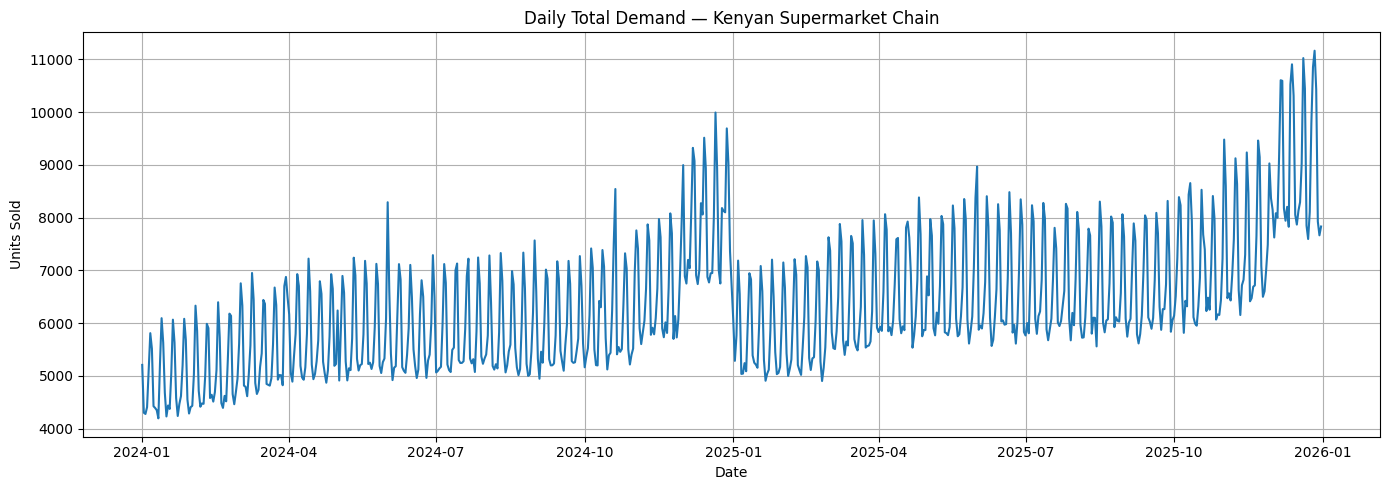

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(
    daily_total["transaction_date"],
    daily_total["daily_quantity"]
)
plt.title("Daily Total Demand — Kenyan Supermarket Chain")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print("daily_total exists:", "daily_total" in globals())
print("daily_demand exists:", "daily_demand" in globals())
print("demand_features exists:", "demand_features" in globals())
print("sales_final exists:", "sales_final" in globals())
print("sales_validated exists:", "sales_final" in globals())


daily_total exists: True
daily_demand exists: True
demand_features exists: True
sales_final exists: True
sales_validated exists: True


In [ ]:
from pathlib import Path

PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save validated sales
sales_final.to_csv(
    PROCESSED_DIR / "sales_validated.csv", index=False
)

# Save daily demand
daily_total.to_csv(
    PROCESSED_DIR / "daily_total.csv", index=False
)

# Save forecasting features
demand_features.to_csv(
    PROCESSED_DIR / "demand_features.csv", index=False
)

print("Saved cleaned data and forecasting datasets:")
print("1. data/processed/sales_validated.csv")
print("2. data/processed/daily_total.csv")
print("3. data/processed/demand_features.csv")

Saved cleaned data and forecasting datasets:
1. data/processed/sales_validated.csv
2. data/processed/daily_total.csv
3. data/processed/demand_features.csv
